In [1]:
import os

# making sure kaggle is installed and up to date
!pip install -q --upgrade kaggle

# creating my kaggle directory and saving my access token
!mkdir -p ~/.kaggle
!echo "KGAT_2fc2808ade30e61818009786e0936d50" > ~/.kaggle/access_token
!chmod 600 ~/.kaggle/access_token

# setting the environment variable here just in case
os.environ["KAGGLE_API_TOKEN"] = "KGAT_2fc2808ade30e61818009786e0936d50"

print("Done setting up Kaggle token.")

Done setting up Kaggle token.


In [2]:
import os

# pulling the bbc news dataset straight from the competition
!kaggle competitions download -c learn-ai-bbc

# unzipping the files into my working folder
!unzip -q -o learn-ai-bbc.zip

# checking what csv files got extracted
print("Extracted files:", [f for f in os.listdir('.') if f.endswith('.csv')])

learn-ai-bbc.zip: Skipping, found more recently modified local copy (use --force to force download)
Extracted files: ['BBC News Test.csv', 'newsbot_dataset.csv', 'BBC News Sample Solution.csv', 'BBC News Train.csv']


In [3]:
import pandas as pd

# reading in the bbc train csv
df = pd.read_csv('BBC News Train.csv')

# renaming the columns so they match our project guidelines
df = df.rename(columns={'Text': 'content', 'Category': 'category'})

# dropping any missing values or duplicates and resetting my index
df = df.dropna(subset=['content', 'category']).drop_duplicates().reset_index(drop=True)

# taking a look at my dataset size and the category breakdown
print(f"Total articles loaded: {df.shape[0]} across {df['category'].nunique()} categories.\n")
print("Breakdown per category:")
print(df['category'].value_counts())
print("\nFirst 2 rows:")
df.head(2)

Total articles loaded: 1490 across 5 categories.

Breakdown per category:
category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

First 2 rows:


,ArticleId,content,category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business


In [4]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# grabbing all the nltk assets including the new punkt_tab resource
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# setting up my stop words list and lemmatizer
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text_pipeline(raw_text):
    # lowering all characters first
    text = raw_text.lower()

    # stripping urls or html tags if any are hanging around
    text = re.sub(r'https?://\S+|www\.\S+|<.*?>', '', text)

    # getting rid of numbers and punctuation symbols
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'[^\w\s]', '', text)

    # tokenizing into words
    tokens = nltk.word_tokenize(text)

    # filtering out stop words and short junk tokens, then lemmatizing down to base forms
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    # returning clean string for tf-idf and modeling
    return " ".join(cleaned_tokens)

# running the cleaning pipeline across all articles
df['clean_content'] = df['content'].apply(clean_text_pipeline)

# saving the preprocessed dataset locally
df.to_csv('newsbot_dataset.csv', index=False)
print("Preprocessing finished! Here's a quick comparison of the first article:\n")
print("Original snippet:")
print(df['content'].iloc[0][:180], "...\n")
print("Cleaned snippet:")
print(df['clean_content'].iloc[0][:180], "...")

Preprocessing finished! Here's a quick comparison of the first article:

Original snippet:
worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witnes ...

Cleaned snippet:
worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers battery fraud charge called company whistleblower first witness cynthia cooper worldcom exhead i ...


TF-IDF matrix shape: 1490 documents by 2500 features.


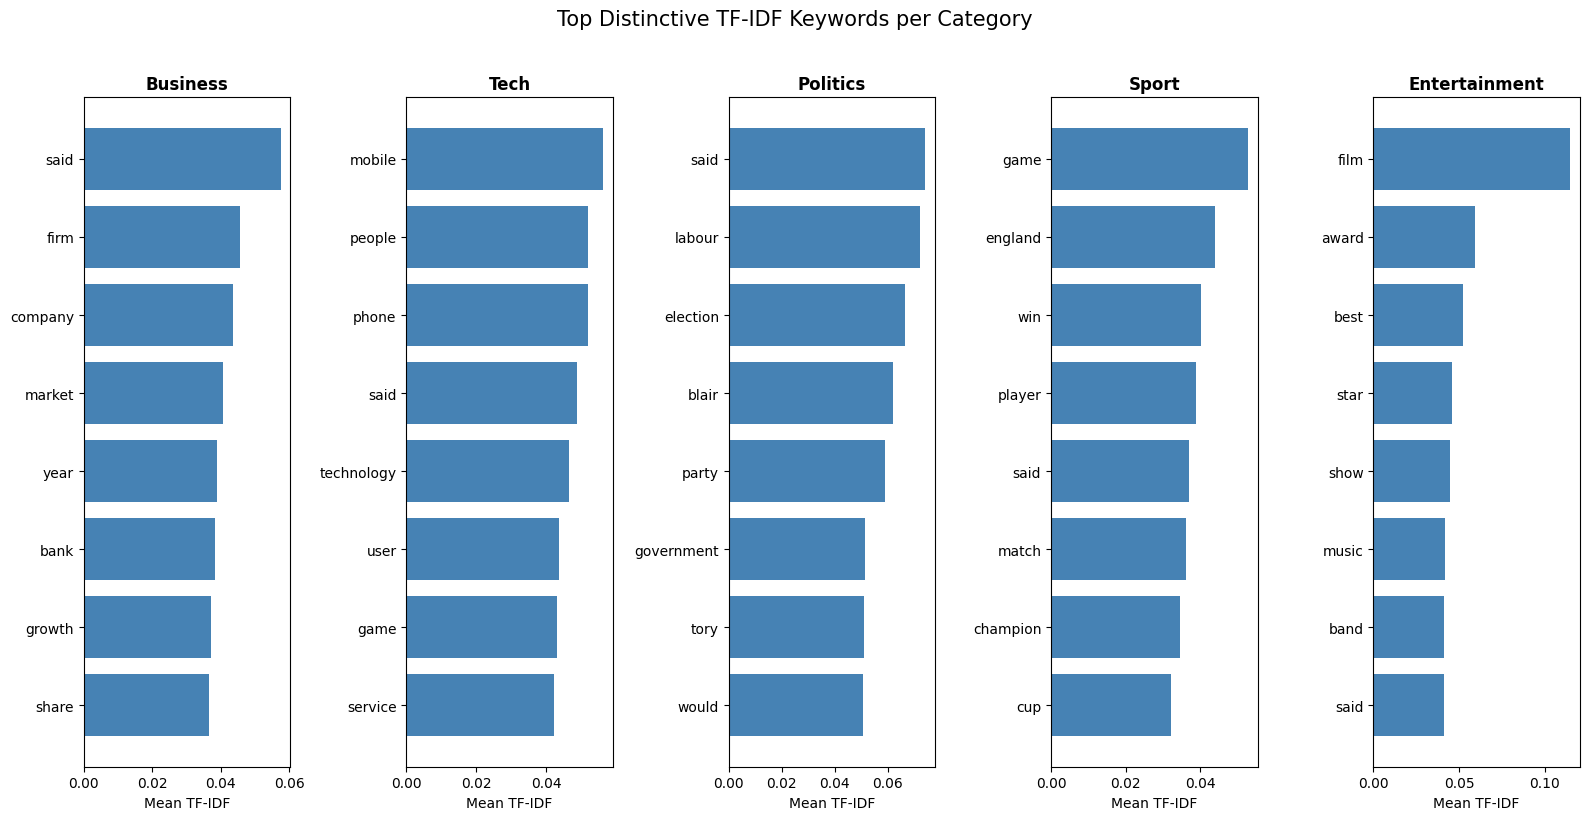

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

# setting up my tf-idf vectorizer with unigrams and bigrams
tfidf = TfidfVectorizer(max_features=2500, ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform(df['clean_content'])

# grabbing the feature names so i can look up the words
feature_names = np.array(tfidf.get_feature_names_out())
print(f"TF-IDF matrix shape: {X_tfidf.shape[0]} documents by {X_tfidf.shape[1]} features.")

# finding the top keywords for each individual category
categories = df['category'].unique()

plt.figure(figsize=(16, 8))

for idx, cat in enumerate(categories):
    # isolating the rows belonging to this category
    cat_mask = (df['category'] == cat).values
    mean_scores = X_tfidf[cat_mask].mean(axis=0).A1

    # pulling the top 8 highest scoring indices
    top_indices = mean_scores.argsort()[-8:][::-1]
    top_words = feature_names[top_indices]
    top_values = mean_scores[top_indices]

    # plotting each category in its own subplot
    plt.subplot(1, 5, idx + 1)
    plt.barh(top_words, top_values, color='steelblue')
    plt.gca().invert_yaxis()
    plt.title(cat.capitalize(), fontsize=12, fontweight='bold')
    plt.xlabel('Mean TF-IDF')

plt.suptitle('Top Distinctive TF-IDF Keywords per Category', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

/tmp/ipykernel_7584/302420898.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample_df = df.groupby('category').apply(lambda x: x.sample(50, random_state=42)).reset_index(drop=True)


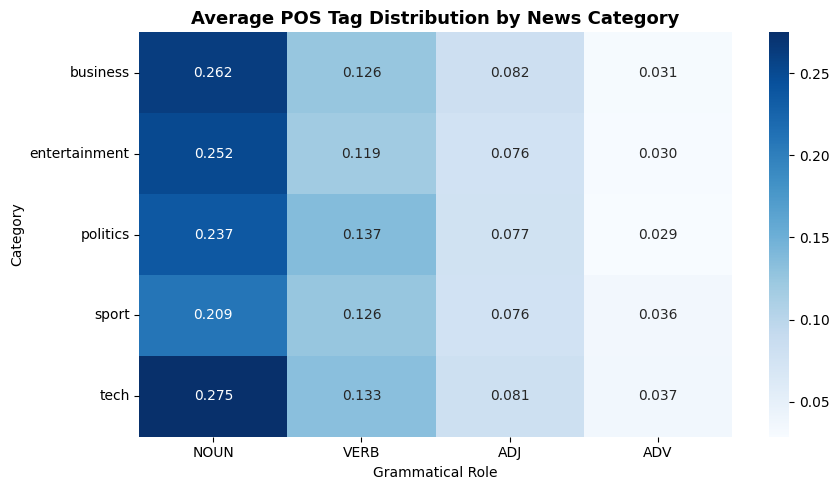

POS analysis complete. Table breakdown:
                   NOUN      VERB       ADJ       ADV
category                                             
business       0.261582  0.125562  0.082011  0.030833
entertainment  0.251686  0.118502  0.075945  0.029844
politics       0.237057  0.136931  0.077289  0.028628
sport          0.209010  0.125606  0.076039  0.036026
tech           0.274916  0.133099  0.080668  0.037042


In [6]:
import spacy
import seaborn as sns
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# loading spacy's small english model
nlp = spacy.load('en_core_web_sm')

# taking a stratified sample of 50 articles per category so parsing stays fast in colab
sample_df = df.groupby('category').apply(lambda x: x.sample(50, random_state=42)).reset_index(drop=True)

def compute_pos_ratios(raw_text):
    # analyzing up to the first 1200 characters per article for efficiency
    doc = nlp(raw_text[:1200])

    # counting coarse pos tags while ignoring punctuation symbols
    pos_counts = Counter([token.pos_ for token in doc if not token.is_punct and not token.is_space])
    total = sum(pos_counts.values()) or 1

    return {
        'NOUN': pos_counts.get('NOUN', 0) / total,
        'VERB': pos_counts.get('VERB', 0) / total,
        'ADJ': pos_counts.get('ADJ', 0) / total,
        'ADV': pos_counts.get('ADV', 0) / total
    }

# calculating the pos distribution across my sample
pos_data = sample_df['content'].apply(compute_pos_ratios)
pos_summary_df = pd.DataFrame(pos_data.tolist())
pos_summary_df['category'] = sample_df['category']

# grouping by category to get average percentages
avg_pos_by_cat = pos_summary_df.groupby('category').mean()

# plotting the grammatical heatmap
plt.figure(figsize=(9, 5))
sns.heatmap(avg_pos_by_cat, annot=True, cmap='Blues', fmt='.3f')
plt.title('Average POS Tag Distribution by News Category', fontsize=13, fontweight='bold')
plt.ylabel('Category')
plt.xlabel('Grammatical Role')
plt.tight_layout()
plt.savefig('pos_distribution_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print("POS analysis complete. Table breakdown:")
print(avg_pos_by_cat)

In [7]:
# building a function to pull subject-verb-object triplets using spacy dependency tags
def extract_svo_triplets(raw_text):
    doc = nlp(raw_text)
    triplets = []

    for token in doc:
        # looking for main action verbs
        if token.pos_ == "VERB":
            # finding the subject pointing to this verb
            subjects = [child.text for child in token.lefts if child.dep_ in ("nsubj", "nsubjpass")]
            # finding direct objects or prepositional objects pointing to this verb
            objects = [child.text for child in token.rights if child.dep_ in ("dobj", "pobj", "attr")]

            if subjects and objects:
                triplets.append((subjects[0], token.lemma_, objects[0]))

    return triplets

# testing it out on three different articles from our sample
print("Testing SVO Extraction on Sample Articles:\n")
for idx in [0, 50, 100]:
    row = sample_df.iloc[idx]
    snippet = row['content'][:400]
    extracted = extract_svo_triplets(snippet)

    print(f"Category: {row['category'].upper()}")
    print(f"Article excerpt: {snippet[:150]}...")
    print(f"Extracted SVO Triplets (Subject -> Action -> Object):")
    for subj, verb, obj in extracted[:4]:
        print(f"  [{subj}] -> ({verb}) -> [{obj}]")
    print("-" * 60)

Testing SVO Extraction on Sample Articles:

Category: BUSINESS
Article excerpt: nasdaq planning $100m share sale the owner of the technology-dominated nasdaq stock index plans to sell shares to the public and list itself on the ma...
Extracted SVO Triplets (Subject -> Action -> Object):
  [nasdaq] -> (plan) -> [sale]
  [observers] -> (see) -> [this]
------------------------------------------------------------
Category: ENTERTAINMENT
Article excerpt: the producers scoops stage awards the producers has beaten mary poppins in the battle of the blockbuster west end musicals at the olivier awards.  the...
Extracted SVO Triplets (Subject -> Action -> Object):
  [producers] -> (scoop) -> [awards]
  [producers] -> (beat) -> [poppins]
  [producers] -> (win) -> [prizes]
  [poppins] -> (win) -> [two]
------------------------------------------------------------
Category: POLITICS
Article excerpt: new  yob  targets to be unveiled fifty new areas getting special help to fight anti-social behaviour i

Sentiment Summary Statistics by Category:
                mean    std  median
category                           
business       0.240  0.837   0.802
entertainment  0.599  0.680   0.968
politics       0.058  0.881   0.380
sport          0.554  0.724   0.966
tech           0.523  0.756   0.955


/tmp/ipykernel_7584/2255140184.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='category', y='sentiment_compound', palette='coolwarm', ax=ax1)


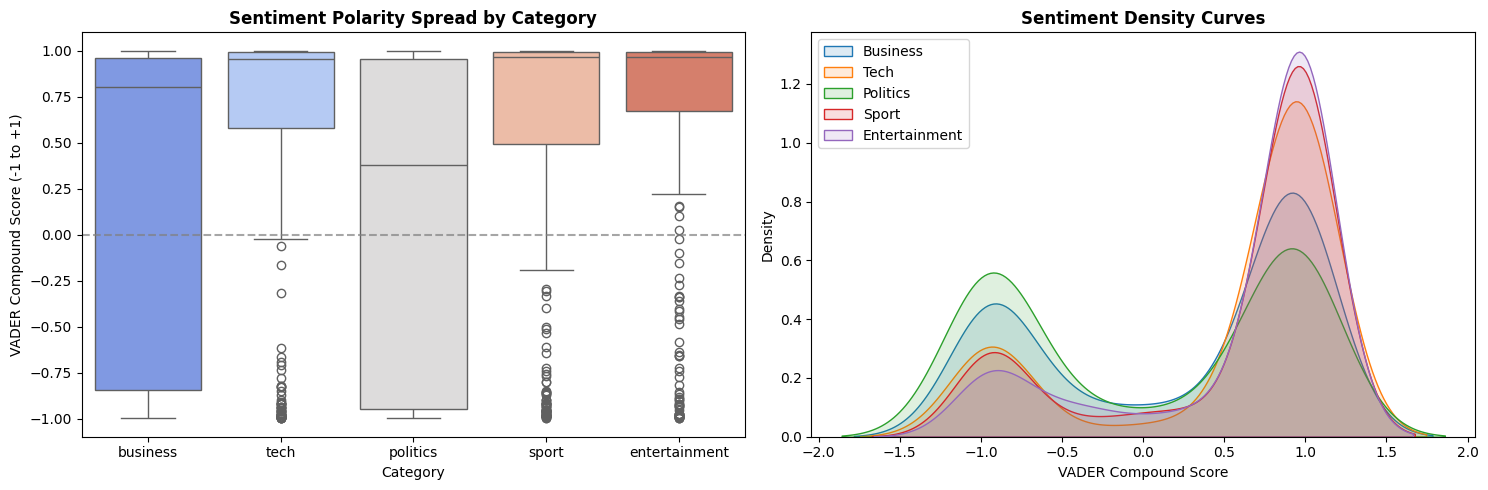

In [8]:
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt
import seaborn as sns

# making sure vader lexicon is loaded
nltk.download('vader_lexicon', quiet=True)
sia = SentimentIntensityAnalyzer()

# scoring compound sentiment across every article
df['sentiment_compound'] = df['content'].apply(lambda text: sia.polarity_scores(text)['compound'])

# calculating average and standard deviation per category
sentiment_summary = df.groupby('category')['sentiment_compound'].agg(['mean', 'std', 'median']).round(3)
print("Sentiment Summary Statistics by Category:")
print(sentiment_summary)

# setting up comparative plots: boxplot and distribution curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# 1. boxplot showing spread and outliers
sns.boxplot(data=df, x='category', y='sentiment_compound', palette='coolwarm', ax=ax1)
ax1.set_title('Sentiment Polarity Spread by Category', fontweight='bold')
ax1.set_ylabel('VADER Compound Score (-1 to +1)')
ax1.set_xlabel('Category')
ax1.axhline(0, color='gray', linestyle='--', alpha=0.7)

# 2. kde distribution curve comparing tones
for cat in df['category'].unique():
    sns.kdeplot(df[df['category'] == cat]['sentiment_compound'], label=cat.capitalize(), ax=ax2, fill=True, alpha=0.15)
ax2.set_title('Sentiment Density Curves', fontweight='bold')
ax2.set_xlabel('VADER Compound Score')
ax2.set_ylabel('Density')
ax2.legend()

plt.tight_layout()
plt.savefig('sentiment_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

Training and benchmarking models:

Multinomial Naive Bayes             -> Accuracy: 0.9698
Logistic Regression                 -> Accuracy: 0.9664
Linear Support Vector Classifier    -> Accuracy: 0.9765

Top Model: Linear Support Vector Classifier with 0.9765 accuracy

Detailed Classification Report for Linear Support Vector Classifier:
               precision    recall  f1-score   support

     business       0.97      0.99      0.98        67
entertainment       0.98      1.00      0.99        55
     politics       0.98      0.93      0.95        55
        sport       0.99      1.00      0.99        69
         tech       0.96      0.96      0.96        52

     accuracy                           0.98       298
    macro avg       0.98      0.97      0.98       298
 weighted avg       0.98      0.98      0.98       298



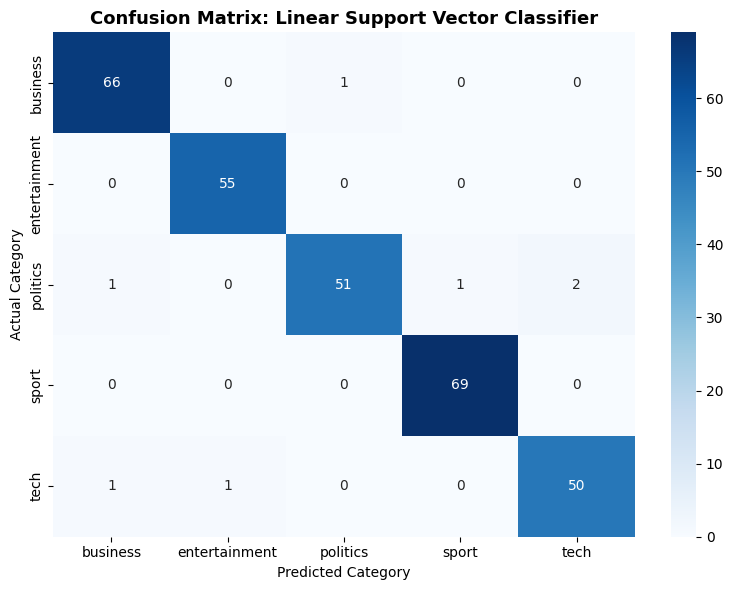

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# setting up features and target labels
X = X_tfidf
y = df['category']

# splitting into 80% train and 20% test with stratification so classes stay balanced
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# initializing the three candidate models
candidate_models = {
    'Multinomial Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Linear Support Vector Classifier': LinearSVC(random_state=42)
}

model_performances = {}

print("Training and benchmarking models:\n")
for name, clf in candidate_models.items():
    # fitting the model on training split
    clf.fit(X_train, y_train)
    # predicting test set
    predictions = clf.predict(X_test)
    acc = accuracy_score(y_test, predictions)
    model_performances[name] = {'model': clf, 'accuracy': acc, 'predictions': predictions}
    print(f"{name:35} -> Accuracy: {acc:.4f}")

# picking the top performing model
best_name = max(model_performances, key=lambda k: model_performances[k]['accuracy'])
best_info = model_performances[best_name]
print(f"\nTop Model: {best_name} with {best_info['accuracy']:.4f} accuracy")

print(f"\nDetailed Classification Report for {best_name}:")
print(classification_report(y_test, best_info['predictions']))

# generating the confusion matrix
labels_order = sorted(df['category'].unique())
cm = confusion_matrix(y_test, best_info['predictions'], labels=labels_order)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_order, yticklabels=labels_order)
plt.title(f'Confusion Matrix: {best_name}', fontsize=13, fontweight='bold')
plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

Entity count breakdown by type:
Label
DATE      1070
PERSON     949
GPE        658
ORG        455
MONEY      192
Name: count, dtype: int64


/tmp/ipykernel_7584/4232183669.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_orgs.values, y=top_orgs.index, palette='mako', ax=ax1)
/tmp/ipykernel_7584/4232183669.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_people.values, y=top_people.index, palette='rocket', ax=ax2)


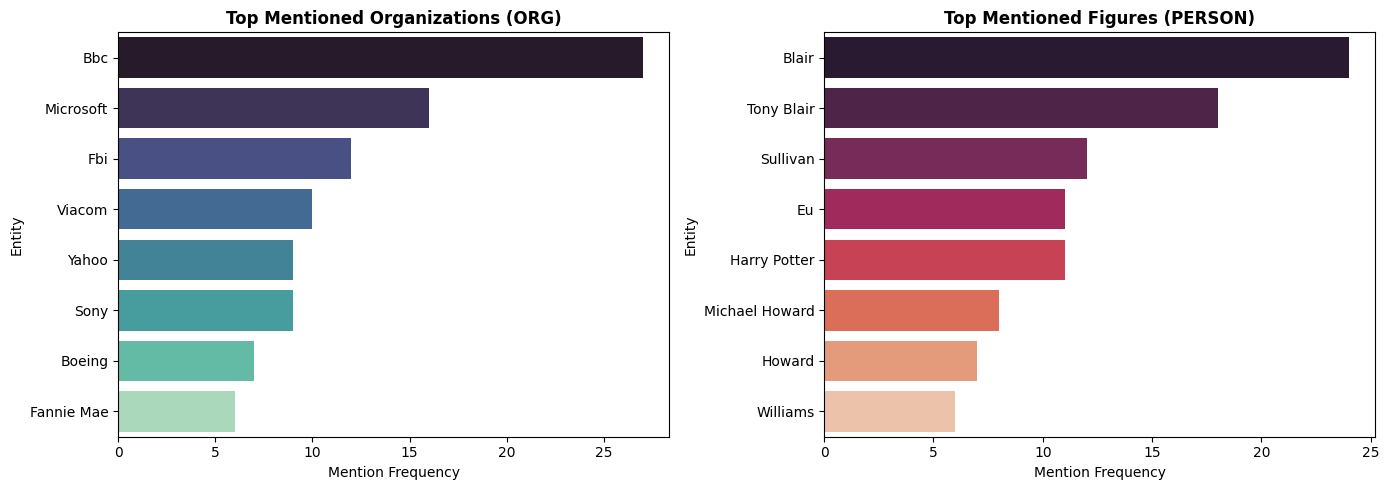


Top 5 Organizations:
Entity
Bbc          27
Microsoft    16
Fbi          12
Viacom       10
Yahoo         9
Name: count, dtype: int64

Top 5 Public Figures:
Entity
Blair           24
Tony Blair      18
Sullivan        12
Eu              11
Harry Potter    11
Name: count, dtype: int64


In [10]:
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# extracting named entities using spacy
target_entity_types = {'PERSON', 'ORG', 'GPE', 'DATE', 'MONEY'}


def extract_entities_from_text(raw_text):
  doc = nlp(raw_text[:1500])
  return [(ent.text, ent.label_) for ent in doc.ents if ent.label_ in target_entity_types]


# running extraction across our sample dataframe
sample_df['extracted_entities'] = sample_df['content'].apply(
    extract_entities_from_text
)

# aggregating entities for tech, business, and politics
all_extracted = [
    (item[0], item[1], sample_df.iloc[idx]['category'])
    for idx, row in enumerate(sample_df['extracted_entities'])
    for item in row
]
entity_df = pd.DataFrame(all_extracted, columns=['Entity', 'Label', 'Category'])

# cleaning up common casing variations
entity_df['Entity'] = (
    entity_df['Entity'].str.strip().str.title()
)

print("Entity count breakdown by type:")
print(entity_df['Label'].value_counts())

# pulling the top organizations and people overall
top_orgs = entity_df[entity_df['Label'] == 'ORG']['Entity'].value_counts().head(8)
top_people = entity_df[entity_df['Label'] == 'PERSON']['Entity'].value_counts().head(8)

# plotting top organizations and figures
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(x=top_orgs.values, y=top_orgs.index, palette='mako', ax=ax1)
ax1.set_title('Top Mentioned Organizations (ORG)', fontweight='bold')
ax1.set_xlabel('Mention Frequency')

sns.barplot(x=top_people.values, y=top_people.index, palette='rocket', ax=ax2)
ax2.set_title('Top Mentioned Figures (PERSON)', fontweight='bold')
ax2.set_xlabel('Mention Frequency')

plt.tight_layout()
plt.savefig('top_entities.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nTop 5 Organizations:")
print(top_orgs.head(5))
print("\nTop 5 Public Figures:")
print(top_people.head(5))

In [11]:
# defining the unified newsbot inference engine
def newsbot_analyze(article_text):
  # 1. clean the incoming text
  cleaned = clean_text_pipeline(article_text)

  # 2. vectorize and predict category using our best model (LinearSVC)
  vectorized_input = tfidf.transform([cleaned])
  predicted_category = candidate_models['Linear Support Vector Classifier'].predict(
      vectorized_input
  )[0]

  # 3. compute sentiment polarity
  sentiment_score = sia.polarity_scores(article_text)['compound']
  sentiment_label = (
      'Positive'
      if sentiment_score >= 0.05
      else ('Negative' if sentiment_score <= -0.05 else 'Neutral')
  )

  # 4. extract named entities and svo action triplets
  doc = nlp(article_text[:2000])
  entities = Counter([
      f"{e.text} ({e.label_})"
      for e in doc.ents
      if e.label_ in target_entity_types
  ]).most_common(5)
  svo_actions = extract_svo_triplets(article_text[:1200])[:3]

  # return a clean, structured summary
  return {
      'Predicted Category': predicted_category.upper(),
      'Sentiment': f'{sentiment_label} ({sentiment_score:.3f})',
      'Top Entities': entities,
      'Extracted Action Triplets': svo_actions,
  }


# testing the pipeline on a brand new, unseen test article
new_test_article = """
Apple today announced its latest artificial intelligence initiative during a major press event in California.
The technology giant plans to invest billions into upgraded data centers and custom silicon chips to accelerate machine learning models.
Wall Street analysts responded enthusiastically, sending shares higher as investors praised the long-term strategic vision.
"""

print("=== NEW ARTICLE LIVE SYSTEM DEMONSTRATION ===")
analysis = newsbot_analyze(new_test_article)
for key, val in analysis.items():
  print(f"\n{key}:")
  print(f"  {val}")

=== NEW ARTICLE LIVE SYSTEM DEMONSTRATION ===

Predicted Category:
  TECH

Sentiment:
  Positive (0.920)

Top Entities:
  [('Apple (ORG)', 1), ('today (DATE)', 1), ('California (GPE)', 1)]

Extracted Action Triplets:
  [('Apple', 'announce', 'initiative'), ('investors', 'praise', 'vision')]
